In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

def OS_fit(xdata,ydata):
    return curve_fit(OS_model, xdata, ydata,
                       p0=[ydata[0], ydata.max(), ydata[-1], 
                           xdata[np.argmax(ydata)], 10 , (xdata[-1]-xdata[np.argmax(ydata)])/2],
                       bounds = ([ydata[0]-0.5, ydata.max()-0.5, ydata[-1]-0.5, 
                                  0, 0, 0],
                                 [ydata[0]+0.5, ydata.max()+0.5, ydata[-1]+0.5, 
                                  len(xdata), 100, len(xdata)]) )

# Loading PROVIDEv1.3 ensemble of FAIR temperatures

In [4]:
folder = '../../Data/PROVIDE 2025/fair_temperatures/'
scenarios = os.listdir(folder)
print(scenarios)

['scen_ModAct nz 2120 decline -16500.csv', 'scen_LD_NZGHG.csv', 'scen_ssp534-over.csv', 'scen_Neg.csv', 'scen_CurPol.csv', 'scen_Ren_NZCO2.csv', 'scen_GS.csv', 'scen_Neg_NZGHG.csv', 'scen_SP_NZGHG.csv', 'scen_LD.csv', 'scen_GS_NZGHG.csv', 'scen_SP.csv', 'scen_Neg nz 2100 decline -17000.csv', 'scen_Ref_1p5.csv', 'scen_CurPol nz 2120 decline -23800.csv', 'scen_ModAct nz 2120 decline -23000.csv', 'scen_Ren.csv', 'scen_ModAct.csv', 'scen_ssp119.csv']


In [5]:
baseline = 'ssp534-over'
df = pd.read_csv(folder+'scen_%s.csv'%baseline)
df=df.set_index('year')
years = df.index.values
temps=df.to_numpy()

In [6]:
temps[-2:,:].mean(axis=0).max()

np.float64(4.2928999999999995)

In [7]:
t_ref = 2015
xdata=years[t_ref-1850:]-t_ref
popts = np.array([OS_fit(xdata,temps[t_ref-1850:,r])[0] for r in range(temps.shape[1])])
popt_of_m,_ = OS_fit(xdata,np.median(temps[t_ref-1850:,:],axis=1))

In [8]:
df_popts = pd.DataFrame(popts,columns=['temp_initial', 'temp_peak', 'temp_stabilisation', 
                                    'time_up','time_plateau','time_down'])
df_popts.head()

,temp_initial,temp_peak,temp_stabilisation,time_up,time_plateau,time_down
0,1.172023,2.416829,1.190184,36.945659,6.689471,87.659344
1,1.024450,1.793498,1.144479,35.661078,6.338934,86.551305
2,0.827063,1.543838,0.914504,35.442296,8.293739,83.542044
3,1.053796,2.765873,2.499009,40.907620,21.707793,43.911215
4,1.026544,2.439644,1.570706,37.271367,9.166675,78.878184


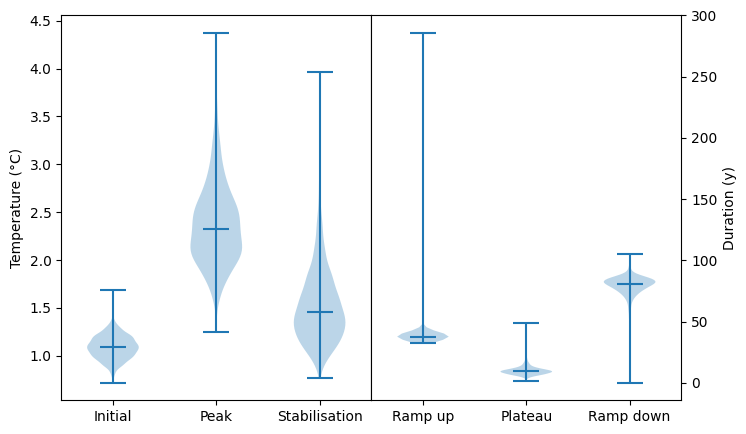

In [10]:
fig,axs=plt.subplots(figsize=(8,5),ncols=2,sharex=False,sharey=False)
fig.subplots_adjust(wspace=0.0)
axs[1].yaxis.set_label_position("right")
axs[1].yaxis.tick_right()

pm=np.median(popts,axis=0)
axs[0].set_xlim(-0.5,2.5)
# axs[0].errorbar(np.arange(3),pm[:3],
#                 yerr=np.abs(np.array([np.quantile(popts[:,:3],q,axis=0) for q in [0.1,0.9]])-pm[:3]),
#                 capsize=5,ls='',marker='x',ms=12)
axs[0].violinplot(popts[:,:3],positions=np.arange(3),showmedians=True)
axs[0].set_xticks(np.arange(3),labels=['Initial','Peak','Stabilisation'])
axs[0].set_ylabel('Temperature (°C)')

axs[1].set_xlim(-0.5,2.5)
# axs[1].errorbar(np.arange(3),pm[3:],
#                 yerr=np.abs(np.array([np.quantile(popts[:,3:],q,axis=0) for q in [0.1,0.9]])-pm[3:]),
#                 capsize=5,ls='',marker='x',ms=12)
axs[1].violinplot(popts[:,3:],positions=np.arange(3),showmedians=True)
axs[1].set_xticks(np.arange(3),labels=['Ramp up','Plateau','Ramp down'])
axs[1].set_ylabel('Duration (y)')
fig.savefig('../../Figures/Overshoots/PROVIDE/ensemble_fitted_parameters.png',bbox_inches='tight')

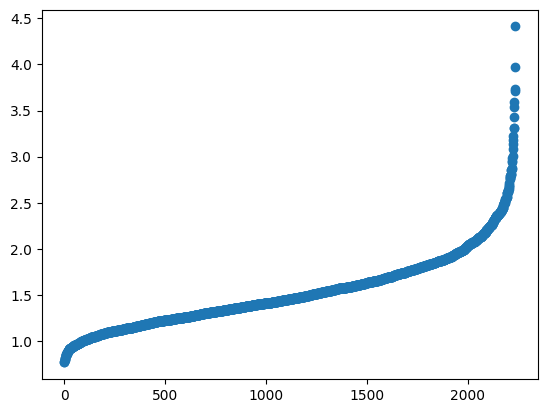

In [83]:
plt.scatter(np.arange(popts.shape[0]),np.sort(popts[:,2]))
# plt.xscale('log')
# plt.yscale('log')

In [ ]:
plt.scatter(np.arange())

In [55]:
idx = np.argsort(popts[:,3])
print(idx[-5:])

[331 859 797 557 511]


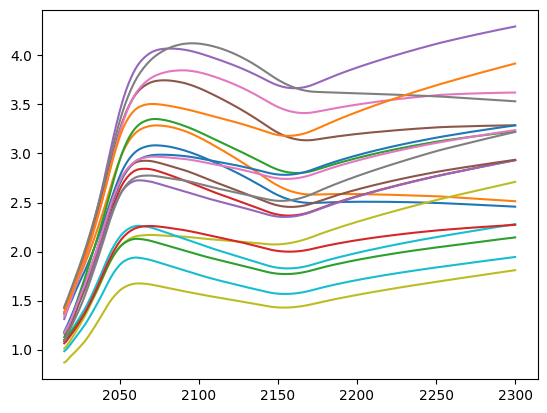

In [60]:
for i in idx[-20:]:
    plt.plot(years[t_ref-1850:], temps[t_ref-1850:,i])

# Aggregate risk for the whole ensemble

In [4]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

In [5]:
temps.shape

(451, 2237)

In [6]:
# Modifying collapse probabilities for each year according to each scenario
p_c = np.ones((temps.shape[1],temps.shape[0],len(df_TEs)))
p_c *= q_c

p_r = np.ones_like(p_c)
p_r *= q_r

for t in range(temps.shape[0]):
    for i in range(temps.shape[1]):
        p_c[i,t,:] *= temp_response(temps[t,i], T_lim, betas)
        p_r[i,t,:] *= (1-temp_response(temps[t,i], T_lim, betas))

In [11]:
D = np.zeros((temps.shape[1],len(df_TEs)))
d_samp = np.zeros((len_sample,len(df_TEs)))
for j in tqdm.tqdm(range(temps.shape[1])):
    for t in range(1,temps.shape[0]):
        for r in range(len_sample):
            d_samp[r,:] = environmental_update(d_samp[r,:],A[r],
                                               pc=p_c[j,t,:],
                                               pr=p_r[j,t,:])
    D[j,:] = d_samp.mean(axis=0)

# Simulating dynamics for TEs without interactions
# D_noint = np.zeros((temps.shape[1],len(df_TEs),no_years))
# for t in tqdm.tqdm(range(1,no_years)):
#     for j in range(len(scenarios)):
#         D_noint[j,:,t] = environmental_update(D_noint[j,:,t-1],np.zeros((len(df_TEs),len(df_TEs))),pc=p_c[j,t,:],pr=p_r[j,t,:])

  0%|▏                                                                              | 4/2237 [00:21<3:20:59,  5.40s/it]


KeyboardInterrupt: 

In [94]:
D = np.zeros((temps.shape[1],len_sample,len(df_TEs),temps.shape[0]))
print(np.nbyte(D))

MemoryError: Unable to allocate 33.8 GiB for an array with shape (2237, 500, 9, 451) and data type float64